# Wildfire Firebreak Containment Simulator

A two-dimensional stochastic cellular-automaton model of wildfire spread, used to study how firebreak width and wind conditions affect the probability that a fire is contained before it crosses a protected boundary. Fire spread is modelled as a discrete-time Markov chain over a grid of cells; Monte Carlo simulation with the law of large numbers is used to estimate containment probability and its uncertainty across repeated stochastic runs.

> This notebook runs top to bottom with *Runtime -> Run all*. It took about 4 minutes on a laptop CPU, so it should finish well within 10 minutes on a free Colab runtime. All random seeds are fixed, so the results are the same every time. The only data file (real wind data used in Section 6.5) is read from the repository, with the original public API as a fallback.

In [1]:
# Setup: install dependencies (already present on Colab, so this finishes in a few seconds)
%pip install -q --disable-pip-version-check numpy matplotlib

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import time

SEED = 42
rng_global = np.random.default_rng(SEED)
print("numpy", np.__version__)

Note: you may need to restart the kernel to use updated packages.


numpy 2.5.1


## 1. Problem and question

Firebreaks are cleared strips of land designed to stop or slow the spread of wildfires by removing fuel (vegetation) in a path across the likely direction of fire travel. In practice, their effectiveness depends on their width, the strength and direction of wind (which can push flames and carry burning embers), and the possibility that embers jump ("spot") across a firebreak and ignite vegetation on the far side.

**Research question:** *How does firebreak width affect the probability of containing a wildfire, under different wind conditions, when ember-spotting is possible?*

This matters because land managers (forestry departments, wildland-urban interface planners) must decide how wide to clear firebreaks given finite resources: wider firebreaks cost more land and labour, but narrow firebreaks may fail to stop a fire, especially in windy conditions where embers can jump further.

**Scope and assumptions:**
- The forest is represented as a uniform 2-D grid; vegetation density, slope and fuel moisture are not modelled explicitly (synthetic/assumed parameters are used throughout, as declared in the topic approval).
- Fire spreads only between orthogonal/diagonal neighbouring cells (Moore neighbourhood), modulated by a wind-direction bias.
- Ember spotting is modelled as a simplified independent random jump across the firebreak, not a physically detailed ember transport model.
- One discrete time step represents one unit of simulated time; cell size and time step are kept fixed across all experiments reported here (sensitivity to resolution is checked in Section 4).

## 2. Model, assumptions and equations

### 2.1 Grid and cell states

The forest is represented as an `L x L` grid. Each cell $c_{i,j}$ is in one of four states:

| Value | State | Meaning |
|---|---|---|
| 0 | Unburned | Has fuel, can ignite |
| 1 | Burning | Actively on fire (lasts exactly one time step in this model) |
| 2 | Burned | Fuel consumed, cannot re-ignite |
| 3 | Firebreak | Cleared strip, no fuel, cannot ignite (except by ember spotting) |

**Units.** The model is dimensionless. One cell is one unit of length (the grid spacing), so firebreak width and ember jump distance are measured in cells. One time step is one unit of time, the time a cell takes to burn out. Probabilities ($p_0$, $p_{	ext{ember}}$) are per cell per time step, and wind strength $s$ is a unitless weight between 0 and 1.

### 2.2 State-transition rule (discrete-time Markov chain)

The grid configuration $X_t = \{c_{i,j,t}\}$ at time $t$ is a discrete-time Markov chain: $X_{t+1}$ depends only on $X_t$ (the current configuration) and independent random draws, not on earlier history. Each cell updates according to:

$$
c_{i,j,t+1} =
\begin{cases}
\text{Burned} & \text{if } c_{i,j,t} = \text{Burning} \\
\text{Burning} & \text{if } c_{i,j,t} = \text{Unburned and } U_{i,j} < p_{i,j,t} \\
\text{Unburned} & \text{if } c_{i,j,t} = \text{Unburned and } U_{i,j} \ge p_{i,j,t} \\
c_{i,j,t} & \text{otherwise (Burned or Firebreak, absorbing)}
\end{cases}
$$

where $U_{i,j} \sim \text{Uniform}(0,1)$ is an independent random draw per cell per time step (random variate generation), and $p_{i,j,t}$ is the ignition probability for an unburned cell, derived below.

### 2.3 Ignition probability and wind influence

Let $n_{i,j,t}$ be the number of **burning** neighbours of cell $(i,j)$ in its Moore neighbourhood (8 surrounding cells) at time $t$, and let $w_{i,j,t}$ be a wind-direction weighting that increases the effective count for neighbours upwind-to-downwind of the wind direction:

$$ p_{i,j,t} = 1 - (1 - p_0)^{\, w_{i,j,t}} $$

where $p_0$ is the base per-neighbour ignition probability. The wind weighting is:

$$ w_{i,j,t} = \sum_{k \in \text{burning neighbours}} \big(1 + s \cdot \max(0, \hat{d}_k \cdot \hat{u})\big) $$

Here $\hat{d}_k$ is the unit vector from the burning neighbour $k$ toward cell $(i,j)$, $\hat{u}$ is the unit wind direction vector, and $s \ge 0$ is the wind strength parameter. The dot product $\hat{d}_k \cdot \hat{u}$ is close to 1 when the fire is spreading in the direction the wind blows, and close to 0 or negative otherwise, so downwind neighbours get a boosted ignition contribution and upwind neighbours do not.

### 2.4 Ember spotting

With a small, independent probability $p_{\text{ember}}$ per burning cell per time step, a burning cell can ignite a cell at a random distance (1 to `max_jump` cells) in the wind direction, regardless of intervening firebreak cells (except that the target cell, if itself a firebreak cell, cannot ignite). This represents airborne embers crossing a cleared strip.

### 2.5 Monte Carlo estimate of containment probability

For a fixed configuration (firebreak width $W$, wind strength $s$, wind direction $\hat u$), containment is a Bernoulli outcome per run: $Y_r = 1$ if the fire is contained (burns out before crossing the firebreak boundary within `max_steps`), else 0. Running $N$ independent replications (different random seeds) gives the Monte Carlo estimator:

$$ \hat{P}_{\text{contain}} = \frac{1}{N}\sum_{r=1}^{N} Y_r, \qquad \text{SE} = \sqrt{\frac{\hat{P}_{\text{contain}}(1-\hat{P}_{\text{contain}})}{N}} $$

By the law of large numbers, $\hat{P}_{\text{contain}} \to P_{\text{contain}}$ as $N \to \infty$; a 95% confidence interval is reported as $\hat{P}_{\text{contain}} \pm 1.96 \cdot \text{SE}$.

**Concepts used:** Markov chains (discrete-time, discrete-state); input modelling and random variate generation (uniform draws for ignition and ember events); Monte Carlo simulation and the law of large numbers (containment probability estimation with confidence intervals).

## 3. Implementation

In [2]:
# Units: lengths are in cells (grid spacing = 1), time is in steps (one step = burn-out time
# of one cell), probabilities are per cell per step, wind strength is a unitless weight in [0, 1].

# --- Cell states ---
UNBURNED, BURNING, BURNED, FIREBREAK = 0, 1, 2, 3

# Moore neighbourhood offsets (8 surrounding cells) with unit direction vectors
NEIGHBOUR_OFFSETS = [(-1,-1),(-1,0),(-1,1),(0,-1),(0,1),(1,-1),(1,0),(1,1)]

def _unit(dx, dy):
    norm = np.hypot(dx, dy)
    return (dx / norm, dy / norm)

WIND_VECTORS = {
    "None":  (0.0, 0.0),
    "North": _unit(0, -1),   # fire pushed toward decreasing row index
    "South": _unit(0, 1),
    "East":  _unit(1, 0),
    "West":  _unit(-1, 0),
}

def make_grid(L, firebreak_width):
    """L x L grid, unburned, with a vertical firebreak strip of given width at the centre column(s)."""
    grid = np.full((L, L), UNBURNED, dtype=np.int8)
    if firebreak_width > 0:
        centre = L // 2
        half = firebreak_width // 2
        start = max(0, centre - half)
        end = min(L, start + firebreak_width)
        grid[:, start:end] = FIREBREAK
    return grid

def ignite_left_edge(grid, rng, n_points=3):
    """Ignite a few cells on the left edge (column 0) to start the fire."""
    L = grid.shape[0]
    rows = rng.choice(L, size=min(n_points, L), replace=False)
    for r in rows:
        if grid[r, 0] == UNBURNED:
            grid[r, 0] = BURNING
    return grid

In [3]:
def step(grid, rng, p0, wind_strength, wind_dir, p_ember, max_jump):
    """Advance the grid by one discrete time step (one Markov-chain transition)."""
    L = grid.shape[0]
    new_grid = grid.copy()
    ux, uy = WIND_VECTORS[wind_dir]

    burning_mask = (grid == BURNING)
    unburned_mask = (grid == UNBURNED)

    # 1) All currently burning cells become burned (burning lasts one step)
    new_grid[burning_mask] = BURNED

    # 2) Unburned cells may ignite based on burning neighbours + wind bias
    burning_coords = np.argwhere(burning_mask)
    w = np.zeros((L, L))
    for (bi, bj) in burning_coords:
        for (di, dj) in NEIGHBOUR_OFFSETS:
            ti, tj = bi + di, bj + dj
            if 0 <= ti < L and 0 <= tj < L and unburned_mask[ti, tj]:
                # direction from burning neighbour (bi,bj) toward target (ti,tj)
                dx, dy = (tj - bj), (ti - bi)
                dd = _unit(dx, dy)
                align = max(0.0, dd[0]*ux + dd[1]*uy)
                w[ti, tj] += 1.0 + wind_strength * align

    p_ignite = 1.0 - (1.0 - p0) ** w
    draws = rng.random((L, L))
    ignite_mask = unburned_mask & (draws < p_ignite)
    new_grid[ignite_mask] = BURNING

    # 3) Ember spotting: burning cells may ignite a distant cell in the wind direction
    if p_ember > 0 and wind_strength > 0 and wind_dir != "None":
        for (bi, bj) in burning_coords:
            if rng.random() < p_ember:
                jump = rng.integers(1, max_jump + 1)
                ti = int(round(bi + uy * jump))
                tj = int(round(bj + ux * jump))
                if 0 <= ti < L and 0 <= tj < L and new_grid[ti, tj] == UNBURNED:
                    new_grid[ti, tj] = BURNING

    return new_grid

In [4]:
def run_simulation(L, firebreak_width, wind_strength, wind_dir, p0=0.25,
                    p_ember=0.0, max_jump=3, max_steps=200, seed=0, record_history=False,
                    stop_at_cross=True, step_fn=None):
    """Run one full stochastic simulation. Returns a dict with the outcome.

    Containment is defined as: fire burns out (no burning cells remain) before
    any cell in the column to the right of the firebreak ever catches fire,
    i.e. the fire never crosses to the protected side.

    stop_at_cross=True (the default, used by all containment estimates) stops the run as
    soon as the fire crosses. stop_at_cross=False lets the fire burn until it goes out,
    which is needed to measure the final burned area.

    step_fn lets Section 6.4 pass the faster vectorised update; None means step().
    """
    stepper = step if step_fn is None else step_fn
    rng = np.random.default_rng(seed)
    grid = make_grid(L, firebreak_width)
    grid = ignite_left_edge(grid, rng)

    centre = L // 2
    half = firebreak_width // 2
    protected_start_col = max(0, centre - half) + max(firebreak_width, 1)

    history = [grid.copy()] if record_history else None
    crossed = False

    for t in range(max_steps):
        grid = stepper(grid, rng, p0, wind_strength, wind_dir, p_ember, max_jump)
        if record_history:
            history.append(grid.copy())
        if np.any(grid[:, protected_start_col:] == BURNING) or np.any(grid[:, protected_start_col:] == BURNED):
            crossed = True
            if stop_at_cross:
                break
        if not np.any(grid == BURNING):
            break  # fire burned itself out

    burned_count = int(np.sum(grid == BURNED) + np.sum(grid == BURNING))
    result = {"contained": not crossed, "burned_cells": burned_count,
              "steps": t + 1, "final_grid": grid}
    if record_history:
        result["history"] = history
    return result

# Quick single-run demo
demo = run_simulation(L=60, firebreak_width=3, wind_strength=0.5, wind_dir="East", seed=SEED)
print(f"Contained: {demo['contained']}, burned cells: {demo['burned_cells']}, steps: {demo['steps']}")

Contained: True, burned cells: 1389, steps: 46


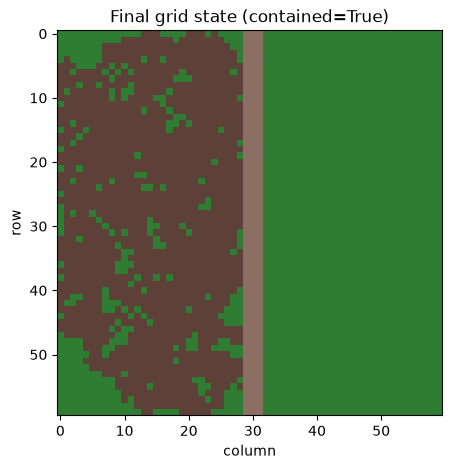

In [5]:
# Visualise one run's final state
cmap = mcolors.ListedColormap(["#2e7d32", "#e53935", "#5d4037", "#8d6e63"])  # unburned, burning, burned, firebreak
norm = mcolors.BoundaryNorm([0,1,2,3,4], cmap.N)

plt.figure(figsize=(5,5))
plt.imshow(demo["final_grid"], cmap=cmap, norm=norm)
plt.title(f"Final grid state (contained={demo['contained']})")
plt.xlabel("column"); plt.ylabel("row")
plt.show()

## 4. Verification

Each check below is shown with an `assert` so the result can be seen to pass directly in the notebook output.

In [6]:
# Check 1: burned cells can never re-ignite (absorbing state)
grid = make_grid(30, 2)
grid = ignite_left_edge(grid, np.random.default_rng(1))
rng_check = np.random.default_rng(1)
prev_burned = np.zeros_like(grid, dtype=bool)
violation = False
for _ in range(60):
    was_burned = (grid == BURNED)
    grid = step(grid, rng_check, p0=0.4, wind_strength=0.3, wind_dir="East", p_ember=0.0, max_jump=3)
    # a cell that was burned must remain burned (never becomes burning/unburned again)
    if np.any(was_burned & (grid != BURNED)):
        violation = True
        break
assert not violation, "a burned cell changed state - re-ignition occurred"
print("PASS: no burned cell ever re-ignited")

PASS: no burned cell ever re-ignited


In [7]:
# Check 2: conservation of total grid cells across every step
L = 40
grid = make_grid(L, 3)
grid = ignite_left_edge(grid, np.random.default_rng(2))
rng_check = np.random.default_rng(2)
total_cells = L * L
ok = True
for _ in range(80):
    grid = step(grid, rng_check, p0=0.35, wind_strength=0.4, wind_dir="North", p_ember=0.02, max_jump=3)
    counts = sum((grid == s).sum() for s in (UNBURNED, BURNING, BURNED, FIREBREAK))
    if counts != total_cells:
        ok = False
        break
assert ok, "total cell count not conserved"
print(f"PASS: total cells conserved at {total_cells} every step")

PASS: total cells conserved at 1600 every step


In [8]:
# Check 3: zero ignition probability -> fire never spreads beyond the initial cells
result_zero = run_simulation(L=40, firebreak_width=2, wind_strength=0.5, wind_dir="East",
                              p0=0.0, p_ember=0.0, max_steps=50, seed=3)
# with p0 = 0, no new ignition can occur, so only the initially-ignited cells ever burn
assert result_zero["burned_cells"] <= 3, "fire spread with zero ignition probability"
print(f"PASS: with p0=0, only {result_zero['burned_cells']} cells burned (the initial ignition points)")

PASS: with p0=0, only 3 cells burned (the initial ignition points)


In [9]:
# Check 4: zero ember-spotting probability + full-width continuous firebreak -> always contained
L = 40
results = [run_simulation(L=L, firebreak_width=L, wind_strength=0.8, wind_dir="East",
                           p0=0.5, p_ember=0.0, max_steps=100, seed=s)["contained"]
           for s in range(20)]
assert all(results), "fire crossed a full-width firebreak with no ember spotting"
print("PASS: a full-width firebreak with no ember spotting contains the fire in all 20 runs")

PASS: a full-width firebreak with no ember spotting contains the fire in all 20 runs


In [10]:
# Check 5: reproducibility - same seed gives identical result
r1 = run_simulation(L=50, firebreak_width=3, wind_strength=0.5, wind_dir="East", p_ember=0.05, seed=123)
r2 = run_simulation(L=50, firebreak_width=3, wind_strength=0.5, wind_dir="East", p_ember=0.05, seed=123)
assert r1["contained"] == r2["contained"] and r1["burned_cells"] == r2["burned_cells"]
print("PASS: identical seed produces identical outcome (contained=%s, burned=%d both runs)"
      % (r1["contained"], r1["burned_cells"]))

PASS: identical seed produces identical outcome (contained=True, burned=553 both runs)


In [11]:
# Check 6: sensitivity to grid resolution - compare containment probability at two grid sizes
def containment_probability(L, firebreak_width, wind_strength, wind_dir, n_runs=60, p0=0.3, p_ember=0.05):
    outcomes = [run_simulation(L=L, firebreak_width=firebreak_width, wind_strength=wind_strength,
                                wind_dir=wind_dir, p0=p0, p_ember=p_ember, seed=s)["contained"]
                for s in range(n_runs)]
    p_hat = np.mean(outcomes)
    se = np.sqrt(p_hat * (1 - p_hat) / n_runs)
    return p_hat, se

p_small, se_small = containment_probability(L=40, firebreak_width=2, wind_strength=0.5, wind_dir="East")
p_large, se_large = containment_probability(L=80, firebreak_width=4, wind_strength=0.5, wind_dir="East")
print(f"L=40, W=2:  P_contain = {p_small:.3f} +/- {1.96*se_small:.3f}")
print(f"L=80, W=4:  P_contain = {p_large:.3f} +/- {1.96*se_large:.3f}")
print("(Firebreak width was scaled with grid size so the relative width is the same."
      " The two values are not the same, so the result does depend on grid resolution;"
      " probabilities reported below are specific to the 50x50 grid used.)")

L=40, W=2:  P_contain = 0.483 +/- 0.126
L=80, W=4:  P_contain = 1.000 +/- 0.000
(Firebreak width was scaled with grid size so the relative width is the same. The two values are not the same, so the result does depend on grid resolution; probabilities reported below are specific to the 50x50 grid used.)


## 5. Experiments and results

Each experiment uses `n_runs=150` independent Monte Carlo replications per configuration, with 95% confidence intervals reported throughout.

**Parameter note:** Experiments 1-3, the summary table, Check 6 above and the sensitivity sweep in 6.3 all call `containment_probability`, whose default base ignition probability is $p_0 = 0.3$, with $p_{\text{ember}} = 0.05$. The single example run in Section 3, the error-scaling check (6.1) and the vegetation-density extension (6.2) pass $p_0 = 0.25$ explicitly. All results are therefore specific to the $p_0$ value stated for each section.

Experiment 1 runtime: 18.2s
width | no wind          | wind 0.6 East
  0   | 0.093 +/- 0.047 | 0.013 +/- 0.018
  1   | 1.000 +/- 0.000 | 0.087 +/- 0.045
  2   | 1.000 +/- 0.000 | 0.440 +/- 0.079
  3   | 1.000 +/- 0.000 | 1.000 +/- 0.000
  4   | 1.000 +/- 0.000 | 1.000 +/- 0.000


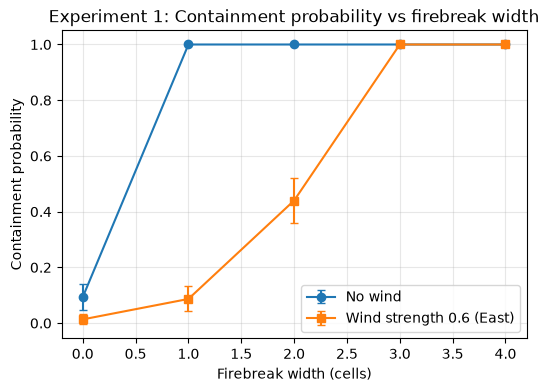

In [12]:
N_RUNS = 150
L = 50

def experiment_vary_width(widths, wind_strength, wind_dir, p_ember=0.05):
    probs, ses = [], []
    for w in widths:
        p, se = containment_probability(L, w, wind_strength, wind_dir, n_runs=N_RUNS, p_ember=p_ember)
        probs.append(p); ses.append(se)
    return np.array(probs), np.array(ses)

widths = [0, 1, 2, 3, 4]
t0 = time.time()
probs_calm, ses_calm = experiment_vary_width(widths, wind_strength=0.0, wind_dir="None")
probs_wind, ses_wind = experiment_vary_width(widths, wind_strength=0.6, wind_dir="East")
print(f"Experiment 1 runtime: {time.time()-t0:.1f}s")
print("width | no wind          | wind 0.6 East")
for w, pc, sc, pw, sw in zip(widths, probs_calm, ses_calm, probs_wind, ses_wind):
    print(f"  {w}   | {pc:.3f} +/- {1.96*sc:.3f} | {pw:.3f} +/- {1.96*sw:.3f}")

plt.figure(figsize=(6,4))
plt.errorbar(widths, probs_calm, yerr=1.96*ses_calm, marker="o", capsize=3, label="No wind")
plt.errorbar(widths, probs_wind, yerr=1.96*ses_wind, marker="s", capsize=3, label="Wind strength 0.6 (East)")
plt.xlabel("Firebreak width (cells)"); plt.ylabel("Containment probability")
plt.title("Experiment 1: Containment probability vs firebreak width")
plt.legend(); plt.grid(alpha=0.3); plt.show()

### Burned area (Experiment 1 settings)

Containment probability says whether the fire crosses, but not how much forest is lost. Here each run is allowed to burn until the fire goes out (`stop_at_cross=False`), and the burned area is reported as the mean share of burnable cells (all cells except the firebreak) that burned, with a 95% confidence interval over the replications. Seeds 0 to N-1 are used, as in the containment estimates.

Burned area runtime: 18.5s
width | burned share, no wind | burned share, wind 0.6 East
  0   | 0.777 +/- 0.050        | 0.928 +/- 0.018
  1   | 0.381 +/- 0.025        | 0.848 +/- 0.036
  2   | 0.372 +/- 0.025        | 0.711 +/- 0.047
  3   | 0.380 +/- 0.025        | 0.468 +/- 0.009
  4   | 0.370 +/- 0.025        | 0.458 +/- 0.009


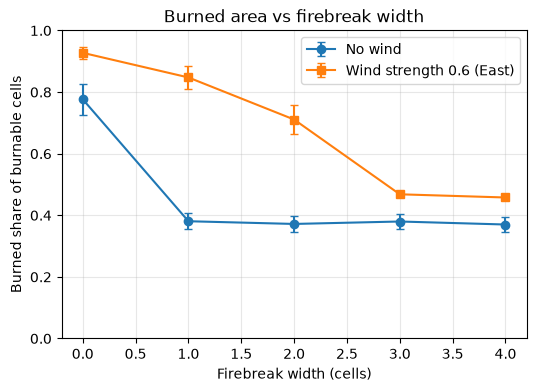

In [13]:
N_BURN = 100

def burned_area(L, firebreak_width, wind_strength, wind_dir, n_runs=N_BURN, p0=0.3, p_ember=0.05):
    """Mean burned share of burnable cells (fire allowed to burn out) and its standard error."""
    burnable = L * L - L * firebreak_width          # every cell except the firebreak strip
    fracs = np.array([run_simulation(L=L, firebreak_width=firebreak_width, wind_strength=wind_strength,
                                     wind_dir=wind_dir, p0=p0, p_ember=p_ember, seed=s,
                                     stop_at_cross=False)["burned_cells"] / burnable
                      for s in range(n_runs)])
    assert np.all((fracs >= 0) & (fracs <= 1)), "burned share must lie in [0, 1]"
    return fracs.mean(), fracs.std(ddof=1) / np.sqrt(n_runs)

t0 = time.time()
area_calm = [burned_area(L, w, 0.0, "None") for w in widths]
area_wind = [burned_area(L, w, 0.6, "East") for w in widths]
print(f"Burned area runtime: {time.time()-t0:.1f}s")
print("width | burned share, no wind | burned share, wind 0.6 East")
for w, (mc, sc), (mw, sw) in zip(widths, area_calm, area_wind):
    print(f"  {w}   | {mc:.3f} +/- {1.96*sc:.3f}        | {mw:.3f} +/- {1.96*sw:.3f}")

plt.figure(figsize=(6,4))
plt.errorbar(widths, [m for m, _ in area_calm], yerr=[1.96*s for _, s in area_calm], marker="o", capsize=3, label="No wind")
plt.errorbar(widths, [m for m, _ in area_wind], yerr=[1.96*s for _, s in area_wind], marker="s", capsize=3, label="Wind strength 0.6 (East)")
plt.xlabel("Firebreak width (cells)"); plt.ylabel("Burned share of burnable cells")
plt.title("Burned area vs firebreak width")
plt.ylim(0, 1); plt.legend(); plt.grid(alpha=0.3); plt.show()

Experiment 2 runtime: 23.0s


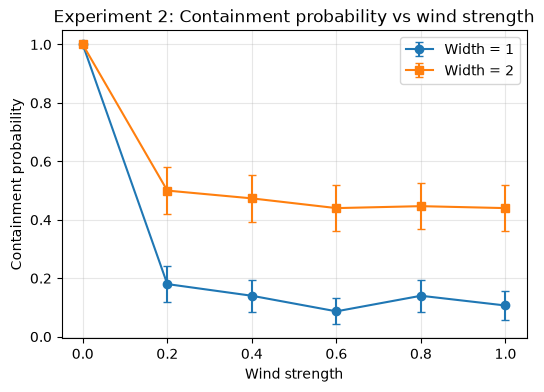

In [14]:
def experiment_vary_wind(wind_strengths, firebreak_width, wind_dir="East", p_ember=0.05):
    probs, ses = [], []
    for s in wind_strengths:
        p, se = containment_probability(L, firebreak_width, s, wind_dir, n_runs=N_RUNS, p_ember=p_ember)
        probs.append(p); ses.append(se)
    return np.array(probs), np.array(ses)

wind_strengths = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
t0 = time.time()
probs_narrow, ses_narrow = experiment_vary_wind(wind_strengths, firebreak_width=1)
probs_wide, ses_wide = experiment_vary_wind(wind_strengths, firebreak_width=2)
print(f"Experiment 2 runtime: {time.time()-t0:.1f}s")

plt.figure(figsize=(6,4))
plt.errorbar(wind_strengths, probs_narrow, yerr=1.96*ses_narrow, marker="o", capsize=3, label="Width = 1")
plt.errorbar(wind_strengths, probs_wide, yerr=1.96*ses_wide, marker="s", capsize=3, label="Width = 2")
plt.xlabel("Wind strength"); plt.ylabel("Containment probability")
plt.title("Experiment 2: Containment probability vs wind strength")
plt.legend(); plt.grid(alpha=0.3); plt.show()

Experiment 3 runtime: 10.7s


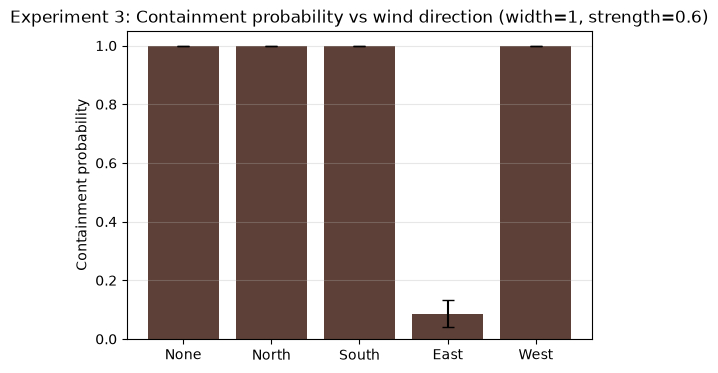

None  : P_contain = 1.000 +/- 0.000
North : P_contain = 1.000 +/- 0.000
South : P_contain = 1.000 +/- 0.000
East  : P_contain = 0.087 +/- 0.045
West  : P_contain = 1.000 +/- 0.000


In [15]:
directions = ["None", "North", "South", "East", "West"]
t0 = time.time()
probs_dir = []
ses_dir = []
for d in directions:
    p, se = containment_probability(L, firebreak_width=1, wind_strength=0.6, wind_dir=d, n_runs=N_RUNS)
    probs_dir.append(p); ses_dir.append(se)
print(f"Experiment 3 runtime: {time.time()-t0:.1f}s")

plt.figure(figsize=(6,4))
plt.bar(directions, probs_dir, yerr=1.96*np.array(ses_dir), capsize=4, color="#5d4037")
plt.ylabel("Containment probability")
plt.title("Experiment 3: Containment probability vs wind direction (width=1, strength=0.6)")
plt.grid(alpha=0.3, axis="y"); plt.show()

for d, p, se in zip(directions, probs_dir, ses_dir):
    print(f"{d:6s}: P_contain = {p:.3f} +/- {1.96*se:.3f}")

In [16]:
# Summary table: minimum firebreak width needed for >= 90% containment, per wind strength
summary_rows = []
for s in [0.0, 0.3, 0.6, 0.9]:
    for w in range(0, 8):
        p, se = containment_probability(L, w, s, "East", n_runs=100)
        if p >= 0.90:
            summary_rows.append((s, w, p))
            break
    else:
        summary_rows.append((s, None, None))

print(f"{'Wind strength':>14} | {'Min width for >=90% containment':>32} | {'P_contain':>10}")
for s, w, p in summary_rows:
    w_str = str(w) if w is not None else "not reached by width 7"
    p_str = f"{p:.3f}" if p is not None else "-"
    print(f"{s:>14} | {w_str:>32} | {p_str:>10}")

 Wind strength |  Min width for >=90% containment |  P_contain
           0.0 |                                1 |      1.000
           0.3 |                                3 |      1.000
           0.6 |                                3 |      1.000
           0.9 |                                3 |      1.000


## 6. Extensions

This section adds five things on top of the core model:

1. A second, independent check of the Monte Carlo estimator, using the way its error shrinks as the number of runs grows.
2. A version of the model with patchy (spatially varying) vegetation density instead of uniform fuel.
3. A sensitivity and uncertainty study over firebreak width and wind strength together.
4. A faster, vectorised version of the update step, checked to give identical results and timed against the original.
5. Real wind data from ten fire seasons on Spetses Island, Greece, used as the model's wind input.

### 6.1 Monte Carlo error scaling

If the containment estimate is a proper Monte Carlo estimator, its standard error should shrink roughly like `1/sqrt(N)` as the number of runs N increases. To check this, the whole estimate is repeated 15 times at each N, the spread (standard deviation) of those repeated estimates is measured, and a straight line is fitted on a log-log plot. The slope should be close to -0.5. This is independent of the experiments in Section 5.

N=  10: mean estimate=0.153, spread (std) over repeats=0.1204


N=  20: mean estimate=0.190, spread (std) over repeats=0.0638


N=  40: mean estimate=0.198, spread (std) over repeats=0.0602


N=  80: mean estimate=0.191, spread (std) over repeats=0.0427


N= 160: mean estimate=0.181, spread (std) over repeats=0.0285

Fitted slope = -0.47 (expected approximately -0.5 for a Monte Carlo estimator)
PASS: error scaling is consistent with 1/sqrt(N)


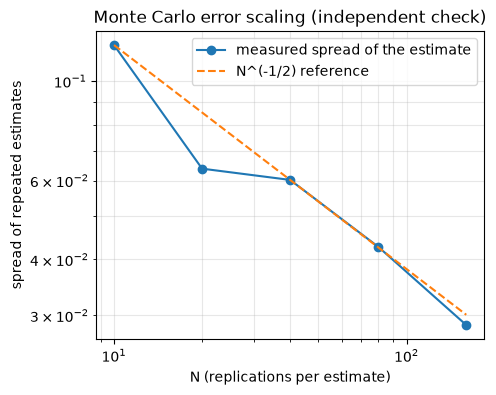

In [17]:
# Monte Carlo error scaling with N
def repeated_estimates(n_reps_of_experiment, N, width=1, wind_strength=0.6, wind_dir="East"):
    """Run the whole N-replication Monte Carlo estimate several times (with different
    seed offsets) to measure how much the estimate itself varies at this N."""
    estimates = []
    for rep in range(n_reps_of_experiment):
        outcomes = [run_simulation(L=50, firebreak_width=width, wind_strength=wind_strength,
                                    wind_dir=wind_dir, p0=0.25, p_ember=0.05,
                                    seed=rep * 10_000 + s)["contained"]
                    for s in range(N)]
        estimates.append(np.mean(outcomes))
    return np.array(estimates)

Ns_x2 = [10, 20, 40, 80, 160]
spreads = []
for N in Ns_x2:
    est = repeated_estimates(n_reps_of_experiment=15, N=N)
    spreads.append(np.std(est))
    print(f"N={N:4d}: mean estimate={np.mean(est):.3f}, spread (std) over repeats={np.std(est):.4f}")

slope_x2 = np.polyfit(np.log(Ns_x2), np.log(spreads), 1)[0]
print(f"\nFitted slope = {slope_x2:.2f} (expected approximately -0.5 for a Monte Carlo estimator)")
assert -0.8 < slope_x2 < -0.2, "measured error scaling is not consistent with Monte Carlo 1/sqrt(N) behaviour"
print("PASS: error scaling is consistent with 1/sqrt(N)")

plt.figure(figsize=(5,4))
plt.loglog(Ns_x2, spreads, "o-", label="measured spread of the estimate")
plt.loglog(Ns_x2, spreads[0] * (np.array(Ns_x2) / Ns_x2[0])**-0.5, "--", label="N^(-1/2) reference")
plt.xlabel("N (replications per estimate)"); plt.ylabel("spread of repeated estimates")
plt.title("Monte Carlo error scaling (independent check)")
plt.legend(); plt.grid(alpha=0.3, which="both"); plt.show()

### 6.2 Patchy vegetation density

The core model assumes the same amount of fuel everywhere. Real forests are patchy, so this extension gives every cell a vegetation density multiplier between about 0.5 and 1.5 (a smooth random field built from a coarse random grid). The base ignition probability `p0` is multiplied by this value, so dense patches catch fire more easily and sparse patches less easily. Firebreak cells still have no fuel. The containment probability is then compared with the uniform-fuel model at the same firebreak width and wind.

Uniform density: P_contain = 0.270 +/- 0.087
Patchy density:  P_contain = 0.380 +/- 0.095


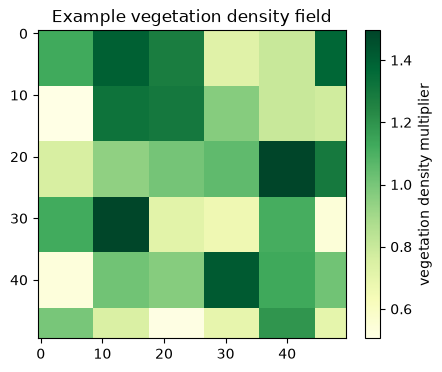

In [18]:
# Patchy vegetation density
def make_density_field(L, rng, low=0.5, high=1.5, patchiness=6):
    """Smoothly varying density multiplier field, values roughly in [low, high],
    built by upsampling a coarse random grid (a simple patchy-fuel approximation)."""
    coarse = rng.uniform(low, high, size=(patchiness, patchiness))
    density = np.kron(coarse, np.ones((L // patchiness + 1, L // patchiness + 1)))[:L, :L]
    return density

def step_with_density(grid, rng, p0, wind_strength, wind_dir, p_ember, max_jump, density):
    """Same transition rule as step(), but the base ignition probability is scaled
    per cell by the local vegetation-density multiplier."""
    L = grid.shape[0]
    new_grid = grid.copy()
    ux, uy = WIND_VECTORS[wind_dir]
    burning_mask = (grid == BURNING)
    unburned_mask = (grid == UNBURNED)
    new_grid[burning_mask] = BURNED
    burning_coords = np.argwhere(burning_mask)
    w = np.zeros((L, L))
    for (bi, bj) in burning_coords:
        for (di, dj) in NEIGHBOUR_OFFSETS:
            ti, tj = bi + di, bj + dj
            if 0 <= ti < L and 0 <= tj < L and unburned_mask[ti, tj]:
                dx, dy = (tj - bj), (ti - bi)
                dd = _unit(dx, dy)
                align = max(0.0, dd[0]*ux + dd[1]*uy)
                w[ti, tj] += 1.0 + wind_strength * align
    p0_field = np.clip(p0 * density, 0.0, 0.999)
    p_ignite = 1.0 - (1.0 - p0_field) ** w
    draws = rng.random((L, L))
    ignite_mask = unburned_mask & (draws < p_ignite)
    new_grid[ignite_mask] = BURNING
    if p_ember > 0 and wind_strength > 0 and wind_dir != "None":
        for (bi, bj) in burning_coords:
            if rng.random() < p_ember:
                jump = rng.integers(1, max_jump + 1)
                ti = int(round(bi + uy * jump))
                tj = int(round(bj + ux * jump))
                if 0 <= ti < L and 0 <= tj < L and new_grid[ti, tj] == UNBURNED:
                    new_grid[ti, tj] = BURNING
    return new_grid

def run_with_density(L, firebreak_width, wind_strength, wind_dir, density_seed, p0=0.25,
                      p_ember=0.05, max_jump=3, max_steps=200, seed=0):
    rng = np.random.default_rng(seed)
    density = make_density_field(L, np.random.default_rng(density_seed))
    grid = make_grid(L, firebreak_width)
    grid = ignite_left_edge(grid, rng)
    centre = L // 2; half = firebreak_width // 2
    protected_start_col = max(0, centre - half) + max(firebreak_width, 1)
    crossed = False
    for t in range(max_steps):
        grid = step_with_density(grid, rng, p0, wind_strength, wind_dir, p_ember, max_jump, density)
        if np.any(grid[:, protected_start_col:] == BURNING) or np.any(grid[:, protected_start_col:] == BURNED):
            crossed = True; break
        if not np.any(grid == BURNING):
            break
    return not crossed, density

# Compare containment probability with uniform vs patchy vegetation density, same firebreak/wind
N_DENSITY = 100
uniform_outcomes = [run_simulation(L=50, firebreak_width=1, wind_strength=0.5, wind_dir="East",
                                    p0=0.25, p_ember=0.05, seed=s)["contained"] for s in range(N_DENSITY)]
patchy_outcomes = [run_with_density(L=50, firebreak_width=1, wind_strength=0.5, wind_dir="East",
                                     density_seed=s, seed=s)[0] for s in range(N_DENSITY)]

p_uniform = np.mean(uniform_outcomes); se_uniform = np.sqrt(p_uniform*(1-p_uniform)/N_DENSITY)
p_patchy = np.mean(patchy_outcomes); se_patchy = np.sqrt(p_patchy*(1-p_patchy)/N_DENSITY)
print(f"Uniform density: P_contain = {p_uniform:.3f} +/- {1.96*se_uniform:.3f}")
print(f"Patchy density:  P_contain = {p_patchy:.3f} +/- {1.96*se_patchy:.3f}")

_, example_density = run_with_density(L=50, firebreak_width=1, wind_strength=0.5, wind_dir="East",
                                       density_seed=7, seed=7)
plt.figure(figsize=(5,4))
plt.imshow(example_density, cmap="YlGn")
plt.colorbar(label="vegetation density multiplier")
plt.title("Example vegetation density field")
plt.show()

### 6.3 Sensitivity and uncertainty

Here firebreak width and wind strength are varied together and the containment probability and its 95% confidence interval are computed for every combination. The first heatmap shows which input matters most; the second shows where the estimate is least certain. For a probability estimated from yes/no outcomes, the interval should be widest near 0.5 and narrowest near 0 or 1.

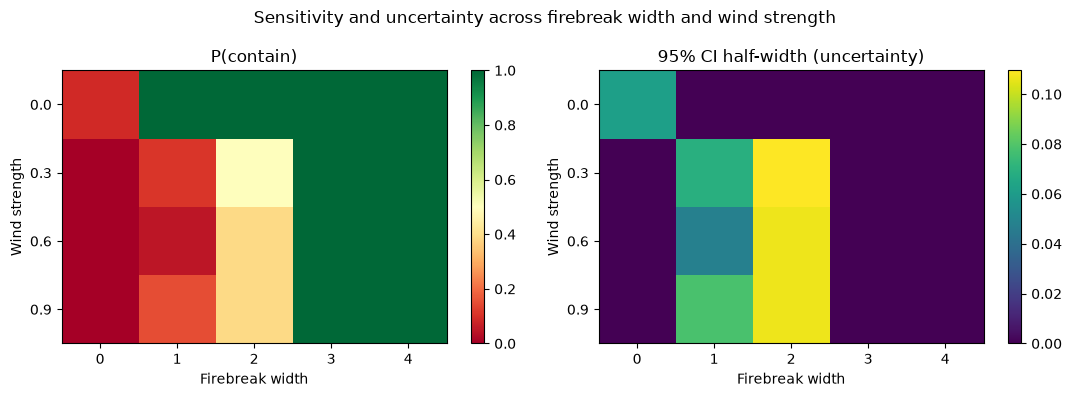

Widest confidence interval at wind=0.3, width=2: P=0.500 +/- 0.110
This is expected near the transition region where containment is neither near 0 nor near 1, since a Bernoulli proportion's standard error is largest at p=0.5.


In [19]:
# Sensitivity and uncertainty: 2D sweep with confidence intervals
widths_sweep = [0, 1, 2, 3, 4]
winds_sweep = [0.0, 0.3, 0.6, 0.9]
N_SWEEP = 80

prob_grid = np.zeros((len(winds_sweep), len(widths_sweep)))
ci_grid = np.zeros((len(winds_sweep), len(widths_sweep)))
for wi, wind_s in enumerate(winds_sweep):
    for ci_i, width in enumerate(widths_sweep):
        p, se = containment_probability(L=50, firebreak_width=width, wind_strength=wind_s,
                                         wind_dir="East", n_runs=N_SWEEP)
        prob_grid[wi, ci_i] = p
        ci_grid[wi, ci_i] = 1.96 * se

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
im0 = axes[0].imshow(prob_grid, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
axes[0].set_xticks(range(len(widths_sweep))); axes[0].set_xticklabels(widths_sweep)
axes[0].set_yticks(range(len(winds_sweep))); axes[0].set_yticklabels(winds_sweep)
axes[0].set_xlabel("Firebreak width"); axes[0].set_ylabel("Wind strength")
axes[0].set_title("P(contain)")
fig.colorbar(im0, ax=axes[0])

im1 = axes[1].imshow(ci_grid, cmap="viridis", aspect="auto")
axes[1].set_xticks(range(len(widths_sweep))); axes[1].set_xticklabels(widths_sweep)
axes[1].set_yticks(range(len(winds_sweep))); axes[1].set_yticklabels(winds_sweep)
axes[1].set_xlabel("Firebreak width"); axes[1].set_ylabel("Wind strength")
axes[1].set_title("95% CI half-width (uncertainty)")
fig.colorbar(im1, ax=axes[1])
plt.suptitle("Sensitivity and uncertainty across firebreak width and wind strength")
plt.tight_layout(); plt.show()

max_ci_idx = np.unravel_index(np.argmax(ci_grid), ci_grid.shape)
print(f"Widest confidence interval at wind={winds_sweep[max_ci_idx[0]]}, width={widths_sweep[max_ci_idx[1]]}: "
      f"P={prob_grid[max_ci_idx]:.3f} +/- {ci_grid[max_ci_idx]:.3f}")
print("This is expected near the transition region where containment is neither near 0 nor near 1,"
      " since a Bernoulli proportion's standard error is largest at p=0.5.")

### 6.4 Performance: vectorised update step

In `step()` the wind-weighted count $w$ is built with a Python loop over every burning cell and its 8 neighbours, so a step gets slower as the fire front grows. `step_fast()` below computes the same $w$ with array operations: for each of the 8 neighbour offsets, the burning mask is shifted by that offset and added with its wind weight $1 + s\max(0,\hat d_k\cdot\hat u)$. That is 8 array additions per step, whatever the size of the fire. The random draws are taken in exactly the same order as in `step()` (one $L\times L$ array for ignition, then the ember loop over burning cells), so with the same seed both versions must give identical grids. The cell checks this with `assert` on single steps and on full runs, then times both versions on the same 100 runs.

PASS: step_fast gives the same grid as step on 300 random grids


width 1, wind 0.6 East  : loop 1.17 s, vectorised 0.38 s, speed-up 3.1x  (identical outcomes in all 100 runs)


width 0, no wind        : loop 0.86 s, vectorised 0.31 s, speed-up 2.8x  (identical outcomes in all 100 runs)


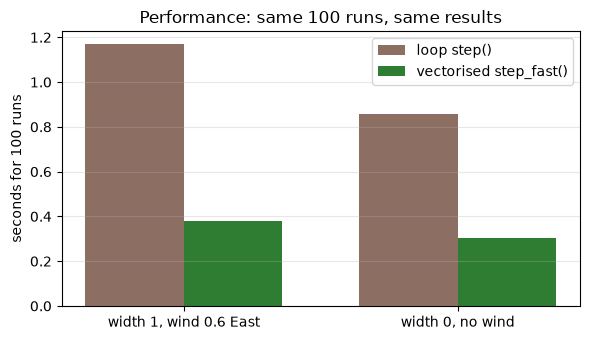

In [20]:
# Performance engineering: vectorised neighbour count, checked against step() and timed
def _offset_weights(wind_strength, wind_dir):
    # wind weight 1 + s*max(0, d.u) for each of the 8 neighbour offsets (same rule as step())
    ux, uy = WIND_VECTORS[wind_dir]
    out = []
    for (di, dj) in NEIGHBOUR_OFFSETS:
        dd = _unit(dj, di)                      # direction from the burning neighbour to the target
        out.append((di, dj, 1.0 + wind_strength * max(0.0, dd[0]*ux + dd[1]*uy)))
    return out

def step_fast(grid, rng, p0, wind_strength, wind_dir, p_ember, max_jump):
    # Vectorised step(): the loop over burning cells is replaced by 8 shifted copies of the burning mask
    L = grid.shape[0]
    new_grid = grid.copy()
    ux, uy = WIND_VECTORS[wind_dir]
    burning_mask = (grid == BURNING)
    unburned_mask = (grid == UNBURNED)
    new_grid[burning_mask] = BURNED

    b = burning_mask.astype(float)
    w = np.zeros((L, L))
    for (di, dj, weight) in _offset_weights(wind_strength, wind_dir):
        # target (i, j) gets the weight of a burning cell at (i - di, j - dj)
        src = b[max(0, -di):L - max(0, di), max(0, -dj):L - max(0, dj)]
        w[max(0, di):L - max(0, -di), max(0, dj):L - max(0, -dj)] += weight * src
    w[~unburned_mask] = 0.0

    p_ignite = 1.0 - (1.0 - p0) ** w
    draws = rng.random((L, L))                  # same draw order as step()
    new_grid[unburned_mask & (draws < p_ignite)] = BURNING

    if p_ember > 0 and wind_strength > 0 and wind_dir != "None":
        for (bi, bj) in np.argwhere(burning_mask):
            if rng.random() < p_ember:
                jump = rng.integers(1, max_jump + 1)
                ti = int(round(bi + uy * jump)); tj = int(round(bj + ux * jump))
                if 0 <= ti < L and 0 <= tj < L and new_grid[ti, tj] == UNBURNED:
                    new_grid[ti, tj] = BURNING
    return new_grid

# 1) single steps on 300 random grids, all wind directions and strengths
rng_grids = np.random.default_rng(7)
for k in range(300):
    g0 = rng_grids.choice([UNBURNED, BURNING, BURNED, FIREBREAK], size=(30, 30), p=[0.6, 0.15, 0.2, 0.05]).astype(np.int8)
    d, s = ["None", "North", "South", "East", "West"][k % 5], [0.0, 0.3, 0.6, 1.0][k % 4]
    assert np.array_equal(step(g0, np.random.default_rng(k), 0.3, s, d, 0.05, 3),
                          step_fast(g0, np.random.default_rng(k), 0.3, s, d, 0.05, 3)), "step_fast differs from step"
print("PASS: step_fast gives the same grid as step on 300 random grids")

# 2) full runs: same outcomes, and timing of the same 100 runs with each version
N_TIME = 100
timings = {}
for label, cfg in [("width 1, wind 0.6 East", dict(firebreak_width=1, wind_strength=0.6, wind_dir="East")),
                   ("width 0, no wind",       dict(firebreak_width=0, wind_strength=0.0, wind_dir="None"))]:
    res = {}
    for name, fn in [("loop", step), ("vectorised", step_fast)]:
        t0 = time.perf_counter()
        res[name] = [run_simulation(L=50, p0=0.3, p_ember=0.05, seed=i, step_fn=fn, **cfg) for i in range(N_TIME)]
        timings[(label, name)] = time.perf_counter() - t0
    assert all(a["contained"] == b["contained"] and a["burned_cells"] == b["burned_cells"] and a["steps"] == b["steps"]
               for a, b in zip(res["loop"], res["vectorised"])), "full runs differ"
    print(f"{label:24s}: loop {timings[(label, 'loop')]:.2f} s, vectorised {timings[(label, 'vectorised')]:.2f} s, "
          f"speed-up {timings[(label, 'loop')] / timings[(label, 'vectorised')]:.1f}x  (identical outcomes in all {N_TIME} runs)")

labels = ["width 1, wind 0.6 East", "width 0, no wind"]
x = np.arange(len(labels))
plt.figure(figsize=(6, 3.5))
plt.bar(x - 0.18, [timings[(l, "loop")] for l in labels], 0.36, label="loop step()", color="#8d6e63")
plt.bar(x + 0.18, [timings[(l, "vectorised")] for l in labels], 0.36, label="vectorised step_fast()", color="#2e7d32")
plt.xticks(x, labels); plt.ylabel(f"seconds for {N_TIME} runs")
plt.title("Performance: same 100 runs, same results")
plt.legend(); plt.grid(alpha=0.3, axis="y"); plt.tight_layout(); plt.show()

### 6.5 Real wind data: Spetses Island fire seasons

The experiments above use chosen wind settings. This extension takes the wind from a real, cited dataset instead: the daily maximum 10 m wind speed and the dominant wind direction for Spetses Island, Greece (37.26 N, 23.15 E), for every day of the June to September fire season from 2015 to 2024 (1,220 days). Spetses is the island whose 1990 wildfire was modelled with a cellular automaton by Alexandridis et al. [3] The values are ERA5 reanalysis data [9] downloaded from the Open-Meteo historical weather API [10] (CC BY 4.0) and saved as `data/spetses_fire_season_wind_2015_2024.csv`.

Processing, one day at a time:

1. The direction the wind blows **toward** is the reported direction plus 180 degrees (weather data gives where the wind comes from). It is rounded to the nearest of north, east, south and west, the four directions the model supports.
2. Wind speed is turned into the model's wind strength with $s = \min(1, v / v_{ref})$, rounded to the nearest 0.2 (minimum 0.2), with $v_{ref} = 40$ km/h (close to the strongest day in the record, 44 km/h). This scaling is an assumption, so the result is repeated with $v_{ref} = 30$ and $50$ km/h.
3. The model's firebreak protects its east side, so for a firebreak protecting side $P$ the wind direction is rotated so that "toward $P$" becomes "East" (a headfire), "away from $P$" becomes "West", and the other two become crosswinds.

The containment probability for each width, direction and strength is estimated once (80 runs each, using `step_fast`), and the real-data answer is the average over the 1,220 days:

$$\hat P_{real}(W, P) = \frac{1}{D}\sum_{d=1}^{D} \hat P\big(W,\ \text{dir}_P(d),\ s(d)\big), \qquad \text{SE}^2 = \sum_{k} f_k^2\,\frac{\hat P_k(1-\hat P_k)}{N}$$

where $f_k$ is the share of days that fall in combination $k$.

Loaded 1220 days from ..\data\spetses_fire_season_wind_2015_2024.csv
Daily max wind speed: median 17.2 km/h, 95th percentile 27.1 km/h, max 44.0 km/h
Share of days the wind blows toward: North 19%, East 16%, South 48%, West 18%


Real-wind table runtime: 45.3s (100 settings x 80 runs)

Containment probability under the real 2015-2024 fire-season winds (v_ref = 40 km/h), +/- 95% CI:
protected side | width 0 | width 1 | width 2 | width 3 | width 4
         North | 0.044+/-0.020 | 0.840+/-0.011 | 0.915+/-0.016 | 1.000+/-0.000 | 1.000+/-0.000
          East | 0.028+/-0.013 | 0.863+/-0.007 | 0.923+/-0.010 | 1.000+/-0.000 | 1.000+/-0.000
         South | 0.023+/-0.010 | 0.581+/-0.023 | 0.764+/-0.034 | 1.000+/-0.000 | 1.000+/-0.000
          West | 0.027+/-0.013 | 0.846+/-0.011 | 0.918+/-0.016 | 1.000+/-0.000 | 1.000+/-0.000

Check of the wind-scaling assumption (south side, width 1 and 2):
  v_ref = 30 km/h: width 1 0.569, width 2 0.735
  v_ref = 40 km/h: width 1 0.581, width 2 0.764
  v_ref = 50 km/h: width 1 0.599, width 2 0.787


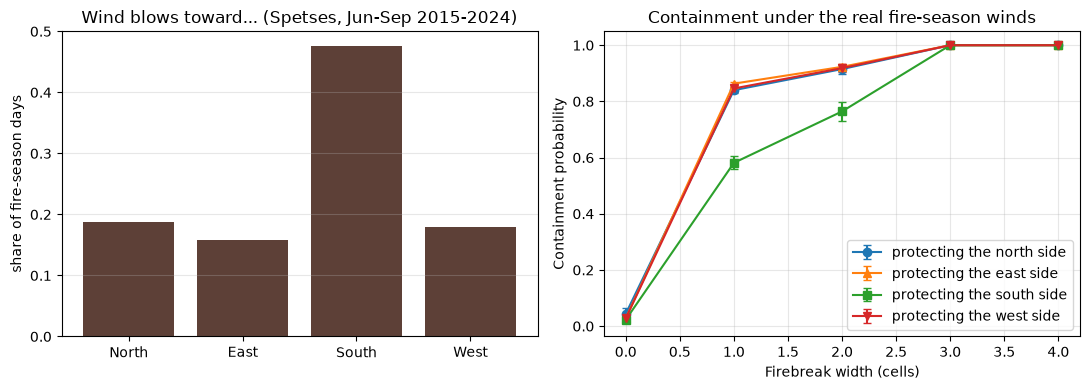

In [21]:
# Real-data grounding: Spetses Island fire-season winds (ERA5 via Open-Meteo, CC BY 4.0)
import io, os, urllib.request

WIND_FILE = "spetses_fire_season_wind_2015_2024.csv"
WIND_SOURCES = [os.path.join("..", "data", WIND_FILE), os.path.join("data", WIND_FILE), os.path.join("..", "Data", WIND_FILE),
                "https://raw.githubusercontent.com/ManithMss/wildfire-firebreak-simulator/main/data/" + WIND_FILE]

def load_wind():
    # local copy first (repository or ZIP), then the public copy in the repository, then the original API
    for src in WIND_SOURCES:
        try:
            text = open(src).read() if not src.startswith("http") else urllib.request.urlopen(src, timeout=30).read().decode()
            return np.genfromtxt(io.StringIO(text), delimiter=",", skip_header=1, usecols=(1, 2)), src
        except Exception:
            continue
    rows = []
    for y in range(2015, 2025):
        url = ("https://archive-api.open-meteo.com/v1/archive?latitude=37.26&longitude=23.15"
               f"&start_date={y}-06-01&end_date={y}-09-30&daily=wind_speed_10m_max,wind_direction_10m_dominant"
               "&timezone=Europe%2FAthens&wind_speed_unit=kmh")
        import json as _json
        d = _json.load(urllib.request.urlopen(url, timeout=60))["daily"]
        rows += list(zip(d["wind_speed_10m_max"], d["wind_direction_10m_dominant"]))
    return np.array(rows, dtype=float), "Open-Meteo API"

wind_data, wind_src = load_wind()
speed_kmh, from_deg = wind_data[:, 0], wind_data[:, 1]
assert len(speed_kmh) == 1220 and not np.isnan(wind_data).any(), "expected 1,220 complete days"
print(f"Loaded {len(speed_kmh)} days from {wind_src}")
print(f"Daily max wind speed: median {np.median(speed_kmh):.1f} km/h, 95th percentile {np.percentile(speed_kmh, 95):.1f} km/h, max {speed_kmh.max():.1f} km/h")

SIDES = ["North", "East", "South", "West"]                     # compass side index 0..3
toward_side = (np.round(((from_deg + 180) % 360) / 90) % 4).astype(int)
share_toward = np.bincount(toward_side, minlength=4) / len(toward_side)
assert abs(share_toward.sum() - 1) < 1e-12
print("Share of days the wind blows toward:", ", ".join(f"{s} {f:.0%}" for s, f in zip(SIDES, share_toward)))

def strength_level(v, v_ref):
    return np.clip(np.round(np.minimum(1.0, v / v_ref) / 0.2) * 0.2, 0.2, 1.0).round(1)

# containment probability for every width x model direction x strength (computed once, reused for every side and v_ref)
S_LEVELS, WIDTHS_REAL, N_REAL = [0.2, 0.4, 0.6, 0.8, 1.0], [0, 1, 2, 3, 4], 80
t0 = time.time()
p_table = {}
for w in WIDTHS_REAL:
    for dname in SIDES:
        for s in S_LEVELS:
            out = [run_simulation(L=50, firebreak_width=w, wind_strength=s, wind_dir=dname, p0=0.3, p_ember=0.05,
                                  seed=i, step_fn=step_fast)["contained"] for i in range(N_REAL)]
            p_table[(w, dname, s)] = np.mean(out)
print(f"Real-wind table runtime: {time.time()-t0:.1f}s ({len(p_table)} settings x {N_REAL} runs)")

def real_wind_containment(protect, v_ref):
    # rotate so that wind toward the protected side is the model's "East" (headfire)
    model_dir = np.array(SIDES)[(toward_side - SIDES.index(protect) + 1) % 4]
    lev = strength_level(speed_kmh, v_ref)
    keys, counts = np.unique(np.stack([model_dir, lev.astype(str)], axis=1), axis=0, return_counts=True)
    f = counts / counts.sum()
    out = []
    for w in WIDTHS_REAL:
        pk = np.array([p_table[(w, k[0], float(k[1]))] for k in keys])
        out.append(((f * pk).sum(), np.sqrt((f**2 * pk * (1 - pk) / N_REAL).sum())))
    return out

print("\nContainment probability under the real 2015-2024 fire-season winds (v_ref = 40 km/h), +/- 95% CI:")
print("protected side | " + " | ".join(f"width {w}" for w in WIDTHS_REAL))
real_res = {}
for side in SIDES:
    real_res[side] = real_wind_containment(side, 40)
    print(f"{side:>14} | " + " | ".join(f"{p:.3f}+/-{1.96*se:.3f}" for p, se in real_res[side]))

print("\nCheck of the wind-scaling assumption (south side, width 1 and 2):")
for v_ref in (30, 40, 50):
    r = real_wind_containment("South", v_ref)
    print(f"  v_ref = {v_ref} km/h: width 1 {r[1][0]:.3f}, width 2 {r[2][0]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(SIDES, share_toward, color="#5d4037")
axes[0].set_ylabel("share of fire-season days"); axes[0].set_title("Wind blows toward... (Spetses, Jun-Sep 2015-2024)")
axes[0].grid(alpha=0.3, axis="y")
for side, mk in zip(SIDES, "o^sv"):
    axes[1].errorbar(WIDTHS_REAL, [p for p, _ in real_res[side]], yerr=[1.96*se for _, se in real_res[side]],
                     marker=mk, capsize=3, label=f"protecting the {side.lower()} side")
axes[1].set_xlabel("Firebreak width (cells)"); axes[1].set_ylabel("Containment probability")
axes[1].set_title("Containment under the real fire-season winds"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 7. Discussion and limitations

**Answer to the research question.** Firebreak width matters a lot. With no firebreak, only about 9% of fires (no wind) or 1% (wind 0.6 East) were contained, and by a width of 3 cells every run was contained (Experiment 1). Wind changes how wide the firebreak needs to be: with no wind a 1-cell firebreak already contains every fire, but with wind toward the firebreak at least 3 cells are needed for 90% containment (summary table).

Experiment 2 shows that the big change happens as soon as there is any wind at all. At width 1, containment drops from 100% with no wind to about 18% at wind strength 0.2, and then stays roughly flat (about 9% to 18%) up to 1.0. Width 2 behaves the same way, levelling off at about 45%. The reason is that ember spotting is only switched on when there is wind, and its probability (0.05) does not grow with wind strength in this model. So most of the effect of "wind" here is really the effect of embers jumping the firebreak, while the wind-weighted spread only adds a little on top.

The biggest effect is wind direction. At width 1 and wind strength 0.6, containment was 100% for no wind, North, South and West wind, but only about 9% for East wind, which blows the fire and its embers straight at the firebreak. This matches what is known about real fires, where a head fire driven by wind is much harder to stop than a fire burning against or across the wind. Once the firebreak is at least as wide as the longest ember jump (3 cells), an ember can only land on firebreak cells, so nothing can get across, which is why containment reaches 100% at width 3.

With real fire-season winds from Spetses Island (Section 6.5), the answer depends on which side the firebreak protects. The summer wind there blows toward the south on almost half of the days, so a firebreak protecting the south side reached only about 0.58 at width 1 and 0.76 at width 2, while on the other three sides width 2 already gave about 0.92. Width 3 contained every run on all sides. This did not change much when the wind-speed scaling was varied.

**Limitations.**
- Slope and fuel moisture are not modelled. The core model uses uniform fuel; Section 6.2 shows that patchy fuel changes the result, so this simplification is not negligible.
- Ember spotting is a simple random jump of 1 to 3 cells with a fixed probability. In reality embers travel further and more often in stronger wind, so making the jump probability and distance depend on wind strength would be the most important improvement.
- Wind is constant during a run, while real wind changes during a large fire.
- The real wind data in Section 6.5 grounds the model's inputs, but the outputs are not validated against observed firebreak outcomes, and the conversion from km/h to the model's wind strength is an assumption.
- Results depend on grid resolution (Check 6 gave 0.483 on a 40x40 grid and 1.000 on an 80x80 grid with the same relative firebreak width), so the probabilities should be read as specific to the 50x50 grid, not as exact real-world values. A proper convergence study over many grid sizes would be the next step.

**Web demo reference check:** the demo's *Notebook reference check* button runs firebreak width 2, wind strength 0.6, wind East, seed 1, 100 runs and gives 0.480 +/- 0.098. Experiment 1 above gives 0.440 +/- 0.079 for the same setting (150 runs). The stated tolerance is 1.96 x sqrt(SE_demo^2 + SE_notebook^2) = 0.126. The difference is 0.040, so the check passes. The values are not identical because the browser uses a different random number generator.


## 8. References

1. A. L. Sullivan, "Wildland surface fire spread modelling, 1990-2007. 1: Physical and quasi-physical models," *International Journal of Wildland Fire*, vol. 18, no. 4, pp. 349-368, 2009, doi: 10.1071/WF06143.
2. I. Karafyllidis and A. Thanailakis, "A model for predicting forest fire spreading using cellular automata," *Ecological Modelling*, vol. 99, no. 1, pp. 87-97, 1997, doi: 10.1016/S0304-3800(96)01942-4.
3. A. Alexandridis, D. Vakalis, C. I. Siettos, and G. V. Bafas, "A cellular automata model for forest fire spread prediction: The case of the wildfire that swept through Spetses Island in 1990," *Applied Mathematics and Computation*, vol. 204, no. 1, pp. 191-201, 2008, doi: 10.1016/j.amc.2008.06.046.
4. D. P. Kroese, T. Taimre, and Z. I. Botev, *Handbook of Monte Carlo Methods*. Hoboken, NJ, USA: Wiley, 2011, doi: 10.1002/9781118014967.
5. D. A. Levin and Y. Peres, *Markov Chains and Mixing Times*, 2nd ed. Providence, RI, USA: American Mathematical Society, 2017, doi: 10.1090/mbk/107.
6. E. Koo, P. J. Pagni, D. R. Weise, and J. P. Woycheese, "Firebrands and spotting ignition in large-scale fires," *International Journal of Wildland Fire*, vol. 19, no. 7, pp. 818-843, 2010, doi: 10.1071/WF07119.
7. A. L. Sullivan, "Wildland surface fire spread modelling, 1990-2007. 2: Empirical and quasi-empirical models," *International Journal of Wildland Fire*, vol. 18, no. 4, pp. 369-386, 2009, doi: 10.1071/WF06142.
8. B. Drossel and F. Schwabl, "Self-organized critical forest-fire model," *Physical Review Letters*, vol. 69, no. 11, pp. 1629-1632, 1992, doi: 10.1103/PhysRevLett.69.1629.
9. H. Hersbach et al., "The ERA5 global reanalysis," *Quarterly Journal of the Royal Meteorological Society*, vol. 146, no. 730, pp. 1999-2049, 2020, doi: 10.1002/qj.3803.
10. P. Zippenfenig, "Open-Meteo.com Weather API," Zenodo, 2024, doi: 10.5281/zenodo.7970649. [Online]. Available: https://open-meteo.com/ (data licence CC BY 4.0).